:::{list-table}
:header-rows: 1
:align: center
:widths: 90 10
* - #
    # Fondamenti di programmazione
    # Canale A-L - Prof. M. Mancini
    # AA 26-27 - Lezione 10
  - :::{image}attachment:5a837f06-202c-4c6e-9259-dd7a6dc01c97.png
    :width: 200px
    :::
:::

# RECAP: Immagini
- creazione/load/save
- rotazione
- disegno di linee verticali/orizzontali/diagonali
- disegno di rettangoli ed ellissi


In [1]:
#%load_ext nb_mypy

In [41]:
from images import load, visd

# definiamo qualche colore
black =   0,   0,   0
white = 255, 255, 255
red   = 255,   0,   0
green =   0, 255,   0
blue  =   0,   0, 255
cyan  =   0, 255, 255
yellow= 255, 255,   0
purple= 255,   0, 255
gray  = 128, 128, 128

# definizione di tipi
Colore   = tuple[int,int,int]
Immagine = list[list[Colore]]

def crea_immagine(larghezza : int, altezza : int, colore : Colore=black) -> Immagine :
    return [  [ colore ]*larghezza 
               for i in range(altezza)
            ]

def draw_pixel(img : Immagine, x : int, y : int, colore : Colore) -> None:
    altezza   = len(img)
    larghezza = len(img[0])
    if  0 <= x < larghezza and 0 <= y < altezza:
        img[y][x] = colore

## Ritagliare una immagine (crop)
- tolgo le righe sopra e sotto
  - ad esempio con una slice (da fare con accuratezza)
- per tutte le righe rimaste
  - tolgo le colonne a sinistra e a destra
     - ad esempio con una slice (da fare con accuratezza)

In [42]:
# tolgo una striscia attorno all'immagine di spessori dati
def crop_image(img : Immagine, alto : int,basso : int,  sx : int, dx :int) -> Immagine :
    L,A = len(img[0]), len(img)
    # i valori di crop devono essere non negativi e non devono sommare a più di L ed A
    assert 0<= alto <A and 0<= basso <A and 0<= sx <L and 0<= dx <L and alto+basso<A and sx+dx<L, f"parametri errati {alto+basso}<{A} {sx+dx}<{L}"
    if basso:    
        fetta = img[alto:-basso] # copio solo il gruppo di righe giuste
    else:        # se basso==0 
        fetta = img[alto:]       # bisogna scrivere così per arrivare in fondo sennò si copia da alto a 0 ovvero nulla
    if dx:       
        return [ riga[sx:-dx] for riga in fetta ] # per ciascuna riga della fetta copio solo la slice di colonne giusta
    else:        # se dx==0 
        return [ riga[sx:] for riga in fetta ] #bisogna scrivere così per arrivare in fondo sennò si copia da sx a 0 ovvero nulla

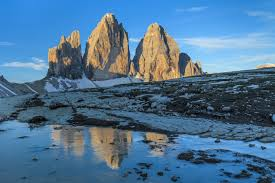

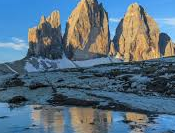

In [43]:
# carico la foto per gli esempi che seguono
img = load('3cime.png')
# esempio
cropped : Immagine = crop_image(img, alto=20, basso=30, sx=20, dx=80)
visd(img), visd(cropped)
None

## Copia e incolla di una parte dell'immagine su un'altra
- con un crop
- e un paste
- con traslazione di coordinate

In [44]:
# per copiare l'immagine (o una sua parte) in un'altra
def cut_paste_img(imgS : Immagine,                            # sorgente
                  imgD : Immagine,                            # destinazione
                  xs1 : int, ys1 : int, xs2 : int, ys2 : int, # rettangolo da copiare
                  XD : int, YD : int ) -> None:               # in che punto
    # FIXME: manca il controllo sui parametri
    # ATTENZIONE: assumo che i parametri siano corretti
    HS = len(imgS)
    WS = len(imgS[0])
    # prima creo il frammento da copiare
    # FIXME: prima di ritagliare calcoliamo quante righe e quante colonne
    # entreranno nell'immagine di destinazione e ritagliamo solo quella parte
    frammento = crop_image(imgS, ys1, HS-ys2, xs1, WS-xs2 )
    # per tutte le righe da copiare
    larghezza = len(frammento[0])
    for yF,riga in enumerate(frammento):
    # uso un assegnamento a slice nella immagine di destinazione
        imgD[yF+YD][XD:XD+larghezza] = riga

# OPPURE senza creare il cropped, copiando solo i pixel giusti (più efficiente)
# PER CASA

### E' SBAGLIATO usare **list.copy** sulla immagine per ottenerne una nuova uguale
Perchè copia <u>solo la lista esterna</u> di righe

e quindi le righe sono condivise tra le due immagini ed ogni modifica fatta a dei pixel si vede nell'altra immagine

Usate **copy.deepcopy** oppure una list-comprehension che copia una riga per volta

In [6]:
from pygraphviz import AGraph
figura = AGraph(directed=True, rankdir='LR')
for i in range(4,-1,-1):
    figura.add_edge(f'img[{i}]', f'riga {i}')
    figura.add_edge(f'riga {i}', f'copia[{i}]', dir='back')
figura.layout('dot')

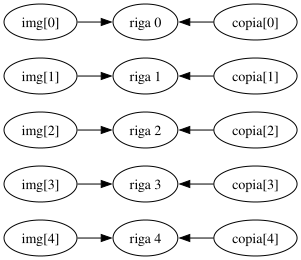

In [7]:
figura

In [47]:
img=load('3cime.png')

# posso copiare l'immagine delle 3 cime di Lavaredo usando un crop nullo
img_copiata = crop_image(img, 0,0,0,0)

# altro modo di copiare una immagine, con una list comprehension che copia ciascuna riga
def copia(img: Immagine) -> Immagine:
    return [ riga.copy() for riga in img ]   # NON BASTA usare solo copy sulla lista esterna!!!

# oppure usando deepcopy
from copy import deepcopy        # SE vi è permesso importare da 'copy'

In [48]:
%time img_copiata = copia(img)

%time img2 = deepcopy(img)

CPU times: user 231 μs, sys: 16 μs, total: 247 μs
Wall time: 258 μs
CPU times: user 61.8 ms, sys: 2.08 ms, total: 63.9 ms
Wall time: 63 ms


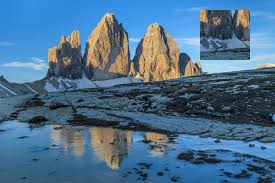

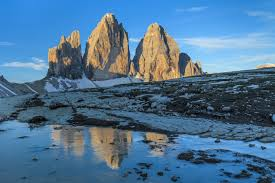

(None, None)

In [49]:
# ne copio un pezzettino in un altro punto per controllare
cut_paste_img(img, img_copiata, 50,50, 100,100, 200,10 )

# come vedete l'originale è rimasta invariata
visd(img_copiata), visd(img)

## Aggiungere un bordo

- creiamo una immagine più grande colorata come il bordo
- ci incolliamo la immagine iniziale

In [50]:
# per aggiungere un bordo 
def add_border(img : Immagine, spessore : int, colore : Colore ) -> Immagine :
    L, A = len(img[0]), len(img)
    # creiamo una immagine più grande col colore del bordo
    nuova = crea_immagine(L+2*spessore,A+2*spessore, colore)
    # ci incolliamo l'immagine originale
    cut_paste_img(img,nuova,0,0,L-1,A-1,spessore,spessore)
    return nuova

### Oppure la creiamo riga per riga (più efficiente)
- un gruppo di righe iniziali colorate per il bordo di sopra
- aggiungiamo alle righe della immagini i bordi sinistro e destro
- agiungiamo il bordo di sotto

In [51]:
# oppure la costruiamo riga per riga
def add_border2(img : Immagine, spessore : int, colore : Colore ) -> Immagine :
    L, A = len(img[0]), len(img)
    bordata = []
    # - prima il bordo superiore dello spessore e lunghezza giusta
    bordata += [ [colore] * (L+2*spessore) for i in range(spessore)  ]

    # - poi per ogni riga dell'immagine aggiungo il bordo a sinistra e destra
    for riga in img:
        #   - spessore pixel + riga + spessore pixel
        bordata.append( [colore]*spessore + riga + [colore]*spessore  )
            
    # - dopo il bordo inferiore dello spessore e lunghezza giusta
    bordata += [ [colore] * (L+2*spessore) for i in range(spessore)  ]
    return bordata

CPU times: user 1.76 ms, sys: 259 μs, total: 2.02 ms
Wall time: 2.92 ms
CPU times: user 1.22 ms, sys: 143 μs, total: 1.36 ms
Wall time: 1.37 ms


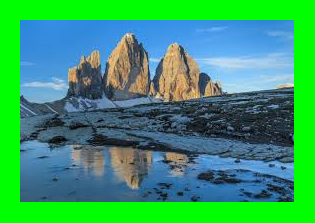

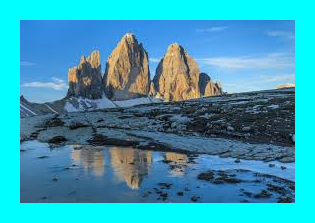

(None, None)

In [52]:
%time bordata = add_border(img, 20, green)
%time bordata2 = add_border2(img, 20, cyan)
visd(bordata) , visd(bordata2)

# Filtri da applicare ai colori
Ogni pixel della immagine viene trasformato in un nuovo colore. Esempi:
  - toni di grigio
  - negativo
  - incremento/riduzione della luminosità
  - incremento/riduzione del contrasto

**NOTA:** questi filtri dipendono solo dal pixel in esame e non dalla sua posizione

## Trasformiamo in una immagine in **toni di grigio**
- creo una copia
- ad ogni pixel della immagine
  - sostituisco il pixel con il grigio che corrisponde alla luminosità media
  
Conviene definire una funzione a parte per la trasformazione del pixel in grigio

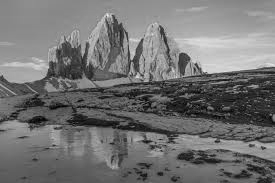

Media


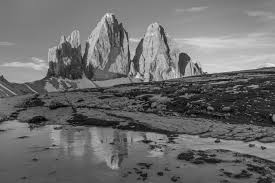

Giusta


In [88]:
# filtro grigio che trasforma un colore in grigio con la stessa luminosità
def filtro_grigio(colore : Colore, modo=False) -> Colore :
    # tutti i pixel devono essere grigi ma con la stessa luminosità totale
    # ovvero R=G=B e R+G+B uguale a prima, quindi bisogna mediare
    if modo:
        grigio = round(sum(colore)/3)   # round torna un intero se il numero di cifre decimali richieste è 0
    else:
        # In realtà il calcolo corretto sarebbe Gray=0.299×R+0.587×G+0.114×B
        R,G,B = colore
        grigio = round(0.299*R+0.587*G+0.114*B)
    return grigio, grigio, grigio     # la media sicuramente è tra 0 e 255 se i valori lo erano

# per trasformare una immagine in livelli di grigio
def grey(img : Immagine, modo=True) -> Immagine :
    # la copio
    grigia = copia(img)
    # e sostituisco ogni pixel col grigio corrispondente
    for y, riga in enumerate(img):
        for x, pixel in enumerate(riga):
            grigia[y][x] = filtro_grigio(pixel, modo)
    return grigia

# esempio
img_grigia = grey(img,True)
img_grigia2 = grey(img,False)
visd(img_grigia,'Media'), visd(img_grigia2,'Giusta')
None

## Cambiamo la **luminosità**
Amplifichiamo/riduciamo di **k** volte la luminosità dell'immagine 

Di nuovo, trasformiamo ciascun pixel **moltiplicando la luminosità per $K$**

Definiamo la trasformazione del pixel in una funzione a parte

In [54]:
from copy import deepcopy

# Ci conviene definire una funzione che vincola il risultato
# ad essere INTERO ed entro un dato INTERVALLO  [m,M] compresi
def bound(canale : float|int, m:int=0, M:int=255 ) -> int:
    "trasformo il valore in intero all'interno di [m..M]"
    canale = round(canale)
    return min(max(canale, m), M)

def filtro_lumi(colore : Colore, k : float) -> Colore:
    "cambiamo la luminosità del pixel di un fattore k su tutti i canali"
    R,G,B = colore
    # mi assicuro che i valori risultanti siano interi nel range 0..255
    return bound(R*k), bound(G*k), bound(B*k)

def luminosità(img : Immagine, k : float) -> Immagine:
    'per schiarire/scurire una immagine di un fattore k (float)'
    copia = deepcopy(img)    # creo una nuova immagine con deepcopy
    # tutti i pixel devono avere una luminosità moltiplicata per k
    for y, riga in enumerate(img):
        for x, colore in enumerate(riga):
            copia[y][x] = filtro_lumi(colore, k)  # sostituisco il pixel
    return copia

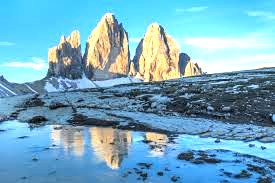

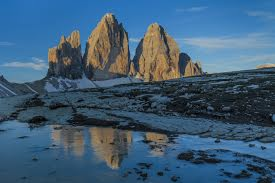

In [55]:
# esempio
img_luminosa = luminosità(img, 1.5)
img_scura    = luminosità(img, 0.8)

visd(img_luminosa), visd(img_scura)
None

## Generalizziamo l'applicazione del filtro
- definendo una trasformazione generica che:
  - accetta come parametro **la funzione che trasforma il pixel**
  - copia l'immagine
    - ripete su ciascun pixel
      - applica la funzione al pixel
  - torna la nuova immagine

In [56]:
from typing import Callable
Filtro = Callable[[Colore], Colore]   # funzione che accetta un Colore e produce un Colore

def applica_filtro( img : Immagine, filtro : Filtro ) -> Immagine:
    'creo una nuova immagine in cui ciascun pixel è trasformato con la funzione filtro(Colore)->Colore'
    # copio l'immagine
    copia = deepcopy(img)
    # tutti i pixel vengono sostituiti con il risultato del filtro
    for y, riga in enumerate(img):
        for x, colore in enumerate(riga):
            copia[y][x] = filtro(colore)   ### QUI eseguo il filtro sul pixel corrente
    return copia

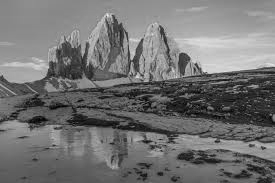

In [57]:
# esempio
# NOTA: per passare la funzione filtro devo usare il solo nome SENZA parentesi()
# come abbiamo fatto per sorted
img_ingrigita = applica_filtro(img, filtro_grigio)
visd(img_ingrigita)

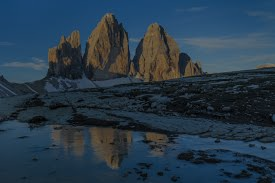

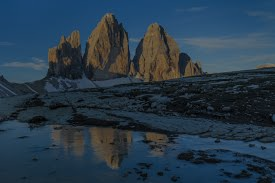

In [58]:
# il filtro deve accettare un solo parametro, il pixel
def piu_scura(pixel):
    "scurisco l'immagine dimezzando la luminosità"
    return filtro_lumi(pixel, 0.5)

scura1 = applica_filtro(img, piu_scura)

# oppure posso usare una lambda
scura2 = applica_filtro(img, lambda pixel: filtro_lumi(pixel, 0.5))
visd(scura1), visd(scura2)
None

## Cambiamo il **contrasto**
- per cambiare il contrasto di un fattore **k**
  - ogni pixel chiaro deve diventare più chiaro
  - ogni pixel scuro deve diventare più scuro
  - ovvero si devono allontanare/avvicinare di un fattore **k** dal grigio **128,128,128**

Quindi per cambiare il contrasto di un pixel di un fattore $k$:
- per ciascuna delle componenti del colore:
  - sottraggio il grigio (128)
  - moltiplico per $k$
  - riaggiungo 128
  - mi assicuro che sia un intero in [0..255]

In [59]:
def filtro_contrasto(colore : Colore, k : float) -> Colore:
    "aumento di un fattore k la distanza del colore da 128, per ciascun canale RGB"
    return tuple( bound((componente-128)*k+128) for componente in colore)

# ovvero
def filtro_contrasto(colore : Colore, k : float) -> Colore:
    "aumento di un fattore k la distanza del colore da 128, per ciascun canale RGB"
    R,G,B = colore
    R1 = bound((R-128)*k + 128)
    G1 = bound((G-128)*k + 128)
    B1 = bound((B-128)*k + 128)
    return R1, G1, B1

# PROBLEMA! : filtro_contrasto vuole DUE parametri, ma applica_filtro vuole un Filtro che ne prende solo 1
# NOTA: mypy non sa che la list comprehension è su 3 elementi per cui gli sembra sbagliato

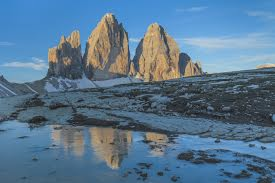

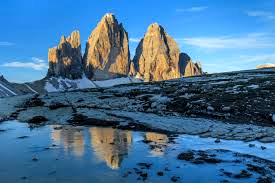

In [60]:
# SOLUZIONE : definisco una lambda che aggiunge K alla chiamata
# esempio
img_più_contrastata  = applica_filtro(img, lambda colore: filtro_contrasto(colore, 1.2))
img_meno_contrastata = applica_filtro(img, lambda colore: filtro_contrasto(colore, 0.8))

visd(img_meno_contrastata), visd(img_più_contrastata)
None

## effetto **Negativo**
Per ottenere l'effetto negativo su un pixel
- per ciascun componente C del colore
  - calcolo la luminosità inversa, ovvero 255-C

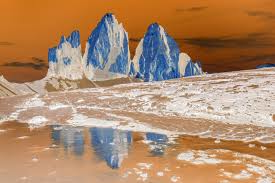

In [61]:
def negativo(colore : Colore ) -> Colore :
    "invertiamo la luminosità di ciascun canale RGB"
    return tuple( 255-componente for componente in colore )

img_negata = applica_filtro(img, negativo)
visd(img_negata)
# di nuovo, mypy non sa dedurre che produrremo sempre una tupla di 3 componenti

## Sfocatura (**blur**)
- facciamo la media dei colori fino a distanza **k** dal pixel

NOTA: questo filtro deve **conoscere la posizione del pixel**

Fa comodo definire:
- come fare la media di un gruppo di colori
- come trovare i vicini di un pixel fino a distanza k (anche sul bordo) 

In [62]:
# calcolo la media di un gruppo di colori
def colore_medio(listaColori : list[Colore]) -> Colore :
    N     = len(listaColori)
    R,G,B = 0, 0, 0
    for r,g,b in listaColori:
        R += r
        G += g
        B += b
    return bound(R/N), bound(G/N), bound(B/N)
    
#oppure
#    return tuple(map(lambda X: bound(sum(X)/N), zip(*listaColori)))

Come raccogliere i vicini fino a distanza K

In [63]:
def vicini(img:Immagine, W:int, H:int, x:int, y:int, k:int):
    # raccolgo i colori del vicinato (stando attento a non sbordare)
    vicinato = []
    for X in range(x-k,x+k+1):
        for Y in range(y-k, y+k+1):
            if 0 <= X < W and 0 <= Y < H: # se sono dentro
                vicinato.append(img[Y][X])
    return vicinato

In [64]:
# per sfocare una immagine entro una distanza k
    # genero una nuova immagine
    # con i pixel che sono la media del gruppo di pixel
    # attorno a quello indicato fino a distanza k
def blur(img : Immagine, k : int) -> Immagine:
    W = len(img[0])
    H = len(img)
    copia = [ riga.copy()  for riga in img ] # invece che deepcopy
    for x  in range(W):      # 
        for y in range(H):
            # raccolgo i colori del vicinato (stando attento a non sbordare)
            vicinato = vicini(img,W,H,x,y,k)
            copia[y][x] = colore_medio(vicinato)
    return copia
# blur è una operazione molto lenta ....

# TODO: realizzarlo come filtro che dipende dalla posizione -> vedi sotto

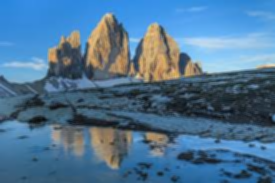

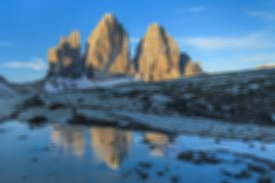

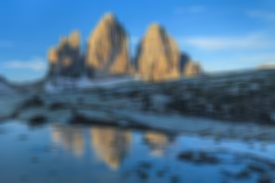

In [65]:
# esempio
img_sfocata1 = blur(img, 1)
img_sfocata2 = blur(img, 2)
img_sfocata3 = blur(img, 3)
visd(img_sfocata1), visd(img_sfocata2), visd(img_sfocata3)
None

## Inseriamo del rumore nella immagine
- possiamo aggiungere del colore a ciascun pixel
- oppure scegliere un pixel vicino (filtro che dipende dalla posizione)

### per aggiungere del rumore al colore del pixel
- per ciascun canale del colore
   - generiamo un valore casuale tra -k e k e lo aggiungiamo
   - ci assicuriamo che sia in [0..255]

In [66]:
from random import randint

# per aggiungere rumore casuale ad una immagine
    # possiamo aggiungere a ciascun pixel un piccolo valore random
def rumore_casuale(colore : Colore, k : int) -> Colore:
    "aggiungiamo a ciascuna componente RGB un piccolo valore in [-k, k]"
    return tuple( bound(C + randint(-k,k)) for C in colore )

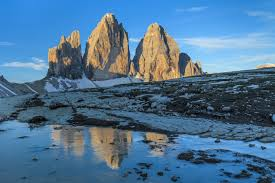

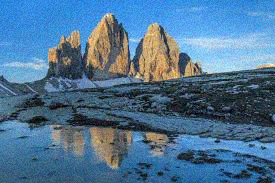

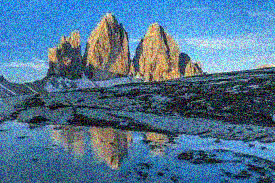

In [67]:
# esempio
poco_rumore  = applica_filtro(img, lambda C: rumore_casuale(C, 20))
tanto_rumore = applica_filtro(img, lambda C: rumore_casuale(C, 50))
visd(img), visd(poco_rumore), visd(tanto_rumore)
None

## Filtri che dipendono dalla posizione
Proviamo a generalizzare i filtri in modo che conoscano: 
- la posizione **x,y** del pixel corrente
- l'immagine sorgente (per leggere altri pixel)
- le dimensioni dell'immagine (per evitare di ricalcolarle)

In [68]:
# - devo sapere dove sono nella immagine e avere accesso a tutta l'immagine!
#                     x    y    img       L    A
FiltroXY = Callable[[int, int, Immagine, int, int], Colore]    # funzione filtro che conosce x,y,img,L,A

def applica_filtro_XY( img : Immagine, filtro : FiltroXY ) -> Immagine:
    'applicazione di un filtro che dipende da x,y, dalla immagine e dalle dimensioni L,A'
    W,H = len(img[0]),len(img)
    # ricevo nell'argomento 'filtro' una funzione che calcola
    # per ogni colore e posizione X,Y il nuovo colore
    copia = deepcopy(img)
    for y in range(H):
        for x in range(W):
            copia[y][x] = filtro(x, y, img, W, H)   ### QUI chiamo il filtro
    return copia

## Esempio: immagine rumorosa per spostamento di pixels
- scegliamo a caso un pixel entro una distanza **k** dal pixel da colorare

In [69]:
# sostituiamo ciascun pixel con un suo vicino preso a caso
def scegli_vicino_a_caso(x : int, y : int, img : Immagine, W : int, H : int, k : int) -> Colore:
    "FiltroXY che legge un pixel a caso entro una distanza k, ma tenendosi dentro l'immagine"
    dx = randint(-k, k)
    dy = randint(-k, k)
    X = bound(x+dx, 0, W-1)  # mi tengo dentro l'immagine
    Y = bound(y+dy, 0, H-1)  # mi tengo dentro l'immagine
    return img[Y][X]

### usiamo una lambda per "togliere" il parametro aggiuntivo k 

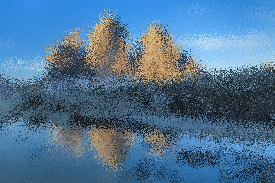

In [70]:
# Esempio con k=5
rumore = applica_filtro_XY(img, lambda x, y, imm, W, H: scegli_vicino_a_caso(x, y, imm, W, H, 5))
visd(rumore)

## Esempio: Pixellazione
possiamo colorare tutti i pixel di ciascun quadratino di dimensioni S in modo simile
- coloro il pixel corrente come il **centro del suo quadratino**
- oppure come la **media del suo quadratino**

### colorazione come il centro del quadratino di dimensione S che racchiude x,y
- date le coordinare x,y del pixel e la dimensione S dei quadratini
  - trovo in quale quadratino mi trovo
    - sottraggo il resto della divisione per S
  - ne trovo il centro
    - aggiungendo S/2
  - mi assicuro di stare nell'immagine
  - e torno quel pixel

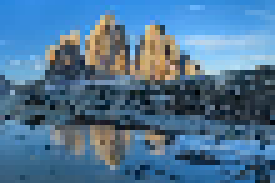

In [72]:
# ad ogni quadrato sostituiamo il colore del suo centro
def pixella(x : int, y : int, img : Immagine, W : int, H : int, S : int) -> Colore :
    'FiltroXY che legge il pixel al centro del suo quadretto'
    X = bound(x-x%S+S/2, 0, W-1) # X del centro
    Y = bound(y-y%S+S/2, 0, H-1) # Y del centro
    return img[Y][X]

pixellata = applica_filtro_XY(img,
            lambda x,y,imm,W,H: pixella(x,y,imm,W,H,5))
visd(pixellata)

### colorazione come <u>la media dei pixel del quadratino</u> di dimensione S che racchiude x,y
- date le coordinare x,y del pixel e la dimensione S dei quadratini
  - trovo in quale quadratino mi trovo
    - sottraggo il resto della divisione per S
  - ne raccolgo i pixel
  - ne calcolo la media (come con blur)
  - e torno un pixel di quel colore

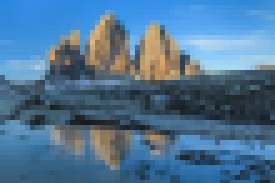

In [74]:
# ad ogni quadrato sostituiamo la *media* dei colori
def pixelmedio(x : int, y : int, img : Immagine, W : int, H : int, S : int) -> Colore :
    'FiltoXY che fa la media dei pixel del quadretto'
    R,G,B, N = 0,0,0, 0
    minx = x-x%S         # bordo sinistro  del quadratino
    miny = y-y%S         # bordo superiore del quadratino
    # raccolgo i pixel del quadratino stando attento a rimanere nella immagine
    vicini = [ img[Y][X]  for X in range(minx, min(W,minx+S))
                          for Y in range(miny, min(H,miny+S)) ]
    return colore_medio(vicini)

## INEFFICIENTE: ricalcola la media per ogni pixel
## MEGLIO: calcolo la media una volta per ogni quadrato
# - ad esempio ricordando il risultato per ogni xmin,ymin,xmax,ymax in un dizionario

pixellata2 = applica_filtro_XY(img, lambda x,y,imm,W,H: pixelmedio(x,y,imm,W,H,5))
visd(pixellata2)

## Blur come filtro
- per ogni pixel calcolo la media del vicinato largo K

In [75]:
def blur_filter(x : int, y : int, img : Immagine, W : int, H : int, k : int) -> Colore:
    "calcolo la media dei vicini fino a distanza k"
    vicini = []
    for X in range(bound(x-k,0,W),bound(x+k+1, 0, W)):
        for Y in range(bound(y-k,0,H),bound(y+k+1, 0, H)):
            vicini.append(img[Y][X])
    # ne torno la media
    return colore_medio(vicini)

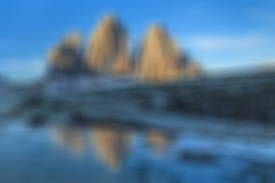

In [78]:
# Esempio con k=3
sfumata = applica_filtro_XY(img, lambda x,y,imm,W,H: blur_filter(x,y,imm,W,H, 6 ))
visd(sfumata)

## Effetto **lente**

Voglio ingrandire/rimpicciolire una zona:
- centrata alle coordinate **x,y**
- di un raggio **r**
- ingrandendo/rimpicciolendo di un fattore **k**
- fuori dalla zona lasciamo l'immagine com'è

## per fare l'effetto lente
Dati:
- il centro xc,yc ed il raggio R della lente
- il fattore K di ingrandimento

Devo:
- calcolare la distanza D dal centro della lente
- tornare lo stesso pixel se sono fuori dalla lente (D>R)
- altrimenti sono dentro la lente
  - ingrandisco di K le due distanze dx e dy tra il punto x,y ed il centro xc,yc
  - torno il pixel che sta in quella posizione

In [36]:
from math import dist
# per dare l'effetto lente
    # nella zona della lente
    # fino a un raggio r
    # mettiamo dei pixel che stanno a distanza K volte 
    # la loro distanza dal centro x1,y1 della lente 

def lente(x : int, y : int, img : Immagine, W : int, H : int, 
          x1 : int, y1 : int, r : int, k : float) -> Colore:
    "FiltroXY che allontana/avvicina i pixel attrorno al centro x,y di un fattore k"
    D = dist((x,y), (x1,y1))        # distanza dal centro
    if D > r:                       # se siamo fuori dal raggio
        return img[y][x]            # lasciamo il pixel com'è (lo leggiamo)
    # altrimenti amplifichiamo le due proiezioni dx e dy di un fattore k
    dx = (x-x1)*k
    dy = (y-y1)*k
    # ci assicuriamo di essere nella immagine
    X = bound(x1+dx,0,W-1)          # alla peggio prendo il pixel del bordo più vicino
    Y = bound(y1+dy,0,H-1)
    return img[Y][X]                # e torniamo il pixel più lontano/vicino al centro

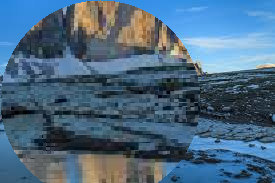

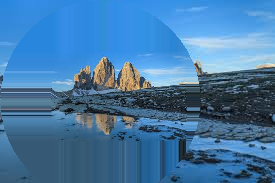

In [37]:
# esempio
# se k<1 prendo i pixel più vicini al centro e l'effetto lente INGRANDISCE (qui k=0.5)
ingrandita    = applica_filtro_XY(img, 
                lambda x, y, img, W, H: lente(x, y, img, W, H, 100, 100, 100, 0.5) )

# se k>1 prendo i pixel più lontani dal centro e l'effetto lente RIMPICCIOLISCE (qui k=2)
rimpicciolita = applica_filtro_XY(img, 
                lambda x, y, img, W, H: lente(x, y, img, W, H, 100, 100, 100, 2  ) )

visd(ingrandita), visd(rimpicciolita)
None